In [2]:
import requests
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords

# Mengunduh dataset stopwords dari NLTK
nltk.download('stopwords')

# Mengambil data dari API DummyJSON
url = "https://dummyjson.com/products?limit=5"
response = requests.get(url)
produk_list = response.json()['products']

# Memasukkan ke DataFrame dan mengambil kolom yang akan diproses
df = pd.DataFrame(produk_list)[['title', 'description']]
display(df.head())

[nltk_data] Downloading package stopwords to C:\Users\Afardhan D
[nltk_data]     S\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,title,description
0,Essence Mascara Lash Princess,The Essence Mascara Lash Princess is a popular...
1,Eyeshadow Palette with Mirror,The Eyeshadow Palette with Mirror offers a ver...
2,Powder Canister,The Powder Canister is a finely milled setting...
3,Red Lipstick,The Red Lipstick is a classic and bold choice ...
4,Red Nail Polish,The Red Nail Polish offers a rich and glossy r...


In [3]:
# Mengatur stopwords menggunakan bahasa Inggris (karena data dummyjson berbahasa Inggris)
stop_words = set(stopwords.words('english'))

def bersihkan_teks(teks):
    # 1. Mengubah ke huruf kecil (Case Folding)
    teks = teks.lower()
    
    # 2. Menghapus tanda baca dan angka (hanya menyisakan huruf a-z dan spasi)
    teks = re.sub(r'[^a-z\s]', '', teks)
    
    # 3. Memecah kalimat menjadi daftar kata
    kata_kata = teks.split()
    
    # 4. Menghapus stopwords
    kata_bersih = [kata for kata in kata_kata if kata not in stop_words]
    
    # Menggabungkan kembali kata-kata menjadi satu kalimat bersih
    return " ".join(kata_bersih)

print(" Fungsi preprocessing siap digunakan!")

 Fungsi preprocessing siap digunakan!


In [4]:
# Membuat kolom baru berisi teks yang sudah dibersihkan
df['clean_description'] = df['description'].apply(bersihkan_teks)

# Menampilkan perbandingan teks asli dan teks bersih
print("--- Hasil Text Preprocessing ---")
display(df[['description', 'clean_description']])

--- Hasil Text Preprocessing ---


,description,clean_description
0,The Essence Mascara Lash Princess is a popular...,essence mascara lash princess popular mascara ...
1,The Eyeshadow Palette with Mirror offers a ver...,eyeshadow palette mirror offers versatile rang...
2,The Powder Canister is a finely milled setting...,powder canister finely milled setting powder d...
3,The Red Lipstick is a classic and bold choice ...,red lipstick classic bold choice adding pop co...
4,The Red Nail Polish offers a rich and glossy r...,red nail polish offers rich glossy red hue vib...


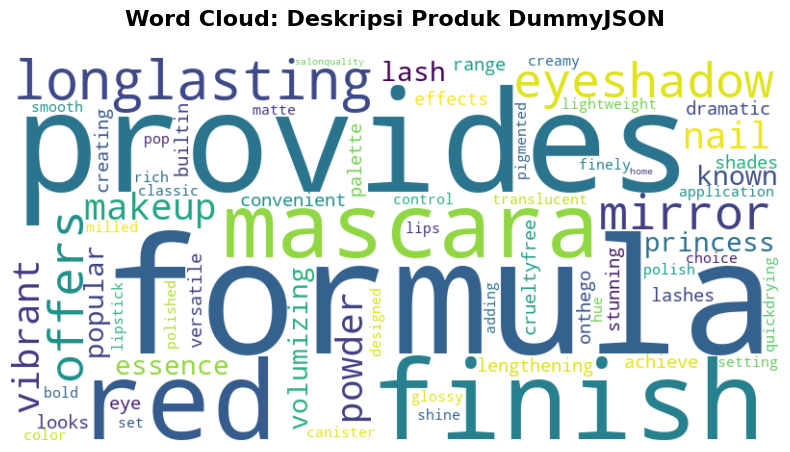

In [5]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# 1. Menggabungkan seluruh teks dari kolom 'clean_description' menjadi satu string teks tunggal
semua_teks = " ".join(df['clean_description'])

# 2. Mengatur konfigurasi WordCloud (ukuran, warna latar, dan tema warna tulisan)
wordcloud = WordCloud(
    width=800, 
    height=400, 
    background_color='white', 
    colormap='viridis', # Bisa diganti tema lain seperti 'plasma', 'magma', 'inferno'
    max_words=100
).generate(semua_teks)

# 3. Menampilkan gambar menggunakan matplotlib
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off') # Menghilangkan garis sumbu X dan Y agar bersih
plt.title('Word Cloud: Deskripsi Produk DummyJSON\n', fontsize=16, fontweight='bold')
plt.show()